
<p align="center">
  <img src="https://images.caradisiac.com/logos/1/1/0/6/261106/S0-l-application-waze-fait-peau-neuve-184080.jpg" width="2000">
</p>


# *Introduction*

Le ***pré-traitement*** des données est une étape cruciale dans tout projet de science des données. Avant d’appliquer des techniques d’analyse ou de modélisation, il est essentiel de s'assurer que les données sont cohérentes, propres et bien structurées. Dans ce notebook, nous allons préparer notre jeu de données afin qu’il soit exploitable pour les étapes suivantes du projet. Même si notre dataset ne contient ni valeurs manquantes ni doublons, certaines opérations sont nécessaires, telles que la vérification des types de variables, la transformation de certaines colonnes, la création de nouvelles variables utiles, ou encore l’adaptation du format des données. Ce travail permettra de garantir une analyse fiable et des résultats pertinents.



# *Objectif*

L’objectif de cette phase est de préparer les données pour une analyse fiable et efficace, même en l'absence de valeurs manquantes ou dupliquées. Cette étape inclut la vérification de la qualité des données, l’ajustement des types de variables si nécessaire, la sélection ou transformation de certaines colonnes pour les rendre plus exploitables

# *Démarche de prétraitement des données*

# *Importation des bibliothéques*

In [1]:
import warnings
import pandas as pd
import numpy as np
import scipy.stats as stats
from datetime import datetime
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import MinMaxScaler


In [76]:
waze = pd.read_csv("Dataset_Projet1\waze_dataset.csv")

<>:1: SyntaxWarning: invalid escape sequence '\w'
<>:1: SyntaxWarning: invalid escape sequence '\w'
C:\Users\USER\AppData\Local\Temp\ipykernel_14520\2114525025.py:1: SyntaxWarning: invalid escape sequence '\w'
  waze = pd.read_csv("Dataset_Projet1\waze_dataset.csv")


In [78]:
data_2=waze.copy()

In [80]:
# On enlève les lignes où la colonne "label" est manquante (NaN)
df_sans_nan = data_2.dropna(subset=['label'])

X =df_sans_nan.drop(columns=['label']) 
y = df_sans_nan['label']

df_unlabeled = data_2[data_2['label'].isna()]

In [82]:
X_train,X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [84]:
#data, test_waze = train_test_split(df_sans_nan, test_size=0.2, random_state=42)

In [86]:
data = pd.concat([X_train, y_train], axis=1)
test_waze = pd.concat([X_test, y_test], axis=1)

In [88]:
print(len(test_waze))

2860


# 1. Nettoyage Initial

In [91]:
# Gestion des IDs (conservation séparée)
user_ids = data['ID'].copy()
data = data.drop('ID', axis=1)
test_waze = test_waze.drop('ID', axis=1)
df_unlabeled = df_unlabeled.drop('ID', axis=1)

# Vérification
print(f"Données après nettoyage : {data.shape[0]} lignes")

Données après nettoyage : 11439 lignes


In [93]:
print(len(test_waze))

2860


In [95]:
print(data.describe())

           sessions        drives  total_sessions  n_days_after_onboarding  \
count  11439.000000  11439.000000    11439.000000             11439.000000   
mean      80.792202     67.401783      189.736398              1756.216278   
std       80.929066     66.130373      136.561755              1008.696060   
min        0.000000      0.000000        0.220211                 4.000000   
25%       23.000000     20.000000       91.318912               888.500000   
50%       57.000000     48.000000      158.516624              1759.000000   
75%      111.000000     93.000000      252.286044              2630.000000   
max      743.000000    596.000000     1216.154633              3500.000000   

       total_navigations_fav1  total_navigations_fav2  driven_km_drives  \
count            11439.000000            11439.000000      11439.000000   
mean               121.047120               29.880234       4029.823491   
std                146.540653               45.410274       2474.649333 

In [97]:
import numpy as np

class Winsorizer:
    def __init__(self, lower_percentile=0.05, upper_percentile=0.95):
        self.lower_percentile = lower_percentile
        self.upper_percentile = upper_percentile
        self.bornes = {}

    def fit(self, df, columns):
        for col in columns:
            q_low = df[col].quantile(self.lower_percentile)
            q_high = df[col].quantile(self.upper_percentile)
            self.bornes[col] = (q_low, q_high)

    def transform(self, df):
        df_copy = df.copy()
        for col, (q_low, q_high) in self.bornes.items():
            df_copy[col] = np.clip(df_copy[col], q_low, q_high)
        return df_copy

    def fit_transform(self, df, columns):
        self.fit(df, columns)
        return self.transform(df)

class LogTransformer:
    def __init__(self):
        self.columns = []

    def fit(self, df, columns):
        self.columns = columns

    def transform(self, df):
        df_copy = df.copy()
        for col in self.columns:
            df_copy[col] = np.log1p(df_copy[col])
        return df_copy

    def fit_transform(self, df, columns):
        self.fit(df, columns)
        return self.transform(df)



In [99]:

winsor_cols = ['sessions', 'drives','total_sessions','total_navigations_fav1','total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives']
log_cols = ['drives','total_sessions','total_navigations_fav1','total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives']
median_cols = ['drives','total_sessions', 'driven_km_drives', 'duration_minutes_drives']

# === 1. Winsorisation ===
winsorizer = Winsorizer()
data = winsorizer.fit_transform(data, winsor_cols)
test_waze = winsorizer.transform(test_waze)
df_unlabeled = winsorizer.transform(df_unlabeled)

# === 2. Transformation logarithmique ===
log_transformer = LogTransformer()
data = log_transformer.fit_transform(data, log_cols)
test_waze = log_transformer.transform(test_waze)
df_unlabeled = log_transformer.transform(df_unlabeled)

robust_scaler = RobustScaler()
data[median_cols] = robust_scaler.fit_transform(data[median_cols])
test_waze[median_cols] = robust_scaler.transform(test_waze[median_cols])
df_unlabeled[median_cols] = robust_scaler.transform(df_unlabeled[median_cols])

In [101]:
print(len(test_waze))

2860


In [103]:
def analyse_outliers(data, outlier_cols):
    for colonne in outlier_cols:
        
        # Calcul des bornes IQR
        Q1 = data[colonne].quantile(0.25)
        Q3 = data[colonne].quantile(0.75)
        IQR = Q3 - Q1
        
        borne_inf = Q1 - 1.5 * IQR
        borne_sup = Q3 + 1.5 * IQR
        
        # Détection des outliers
        outliers = data[(data[colonne] < borne_inf) | (data[colonne] > borne_sup)]
        
        print(f"Variable {colonne} : {len(outliers)} outliers restants")

In [105]:
def analyse_distribution(data, outlier_cols):
    for colonne in outlier_cols:
        print(f"\nAnalyse de la variable : {colonne}")
        print("-" * 60)
        
        # Calcul de la médiane
        median_value = data[colonne].median()
        print(f"Médiane de {colonne} : {median_value:.2f}")
        
        # Visualisation
        plt.figure(figsize=(12, 5))
        sns.histplot(data[colonne], kde=False, color='skyblue')
        plt.axvline(median_value, color='red', linestyle='--', label=f'Médiane = {median_value:.2f}')
        plt.title(f'Histogramme de {colonne}')
        plt.legend()
        plt.tight_layout()
        plt.show()

In [107]:
colonnes = ['sessions', 'drives','total_sessions','total_navigations_fav1','total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives']
analyse_outliers(data, colonnes)

Variable sessions : 0 outliers restants
Variable drives : 0 outliers restants
Variable total_sessions : 0 outliers restants
Variable total_navigations_fav1 : 0 outliers restants
Variable total_navigations_fav2 : 0 outliers restants
Variable driven_km_drives : 0 outliers restants
Variable duration_minutes_drives : 0 outliers restants



Analyse de la variable : sessions
------------------------------------------------------------
Médiane de sessions : 57.00


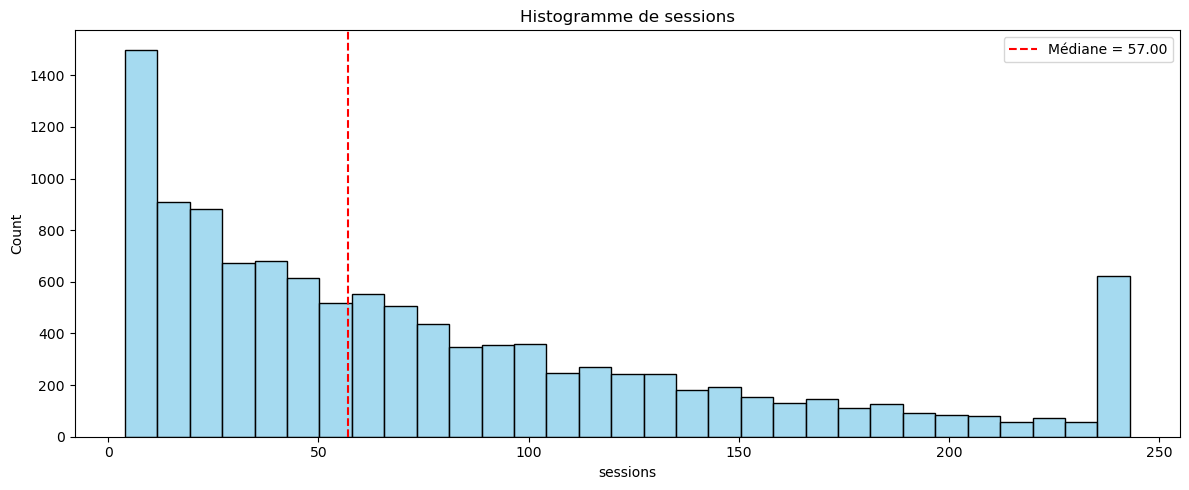


Analyse de la variable : drives
------------------------------------------------------------
Médiane de drives : 0.00


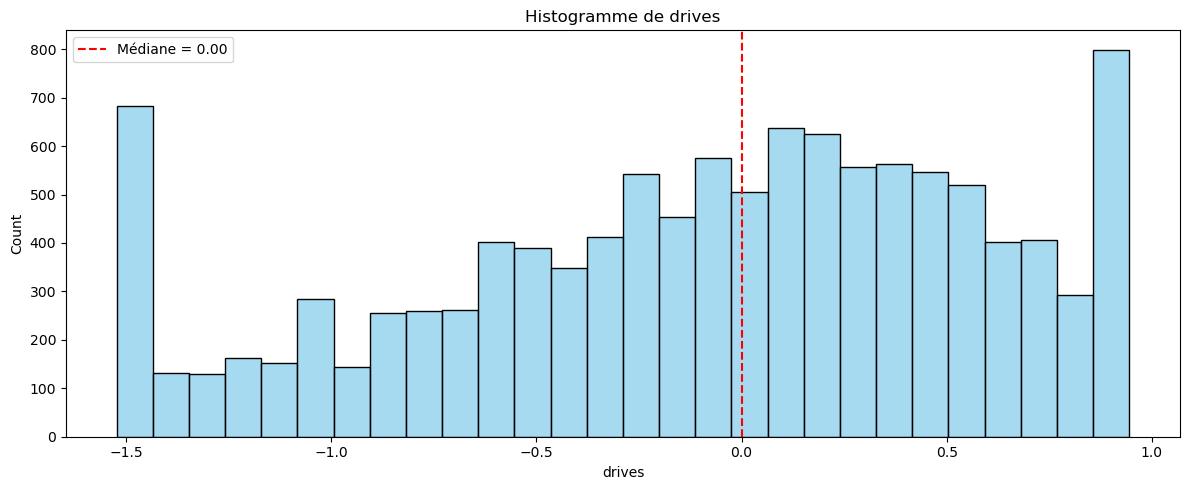


Analyse de la variable : total_sessions
------------------------------------------------------------
Médiane de total_sessions : 0.00


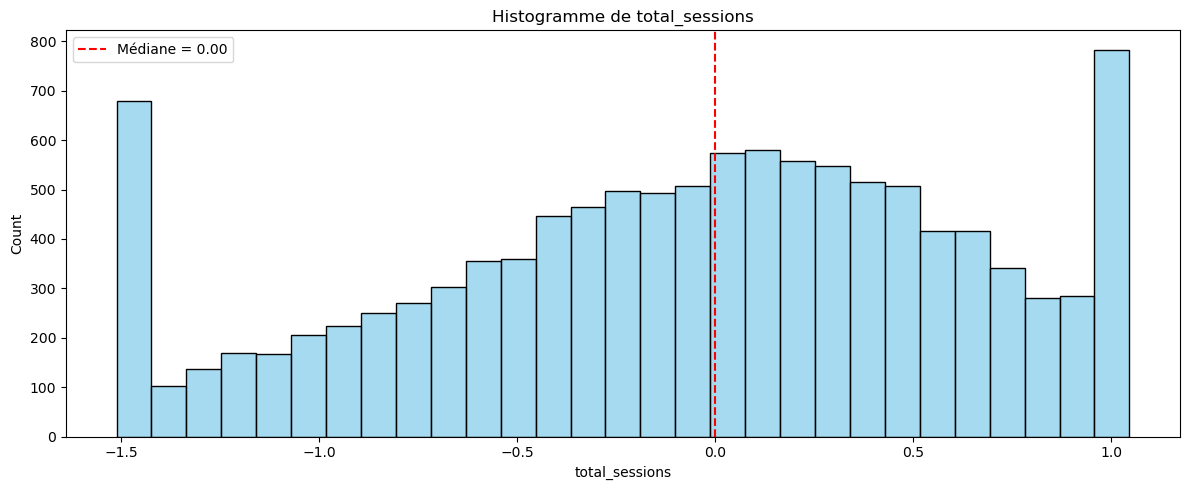


Analyse de la variable : total_navigations_fav1
------------------------------------------------------------
Médiane de total_navigations_fav1 : 4.28


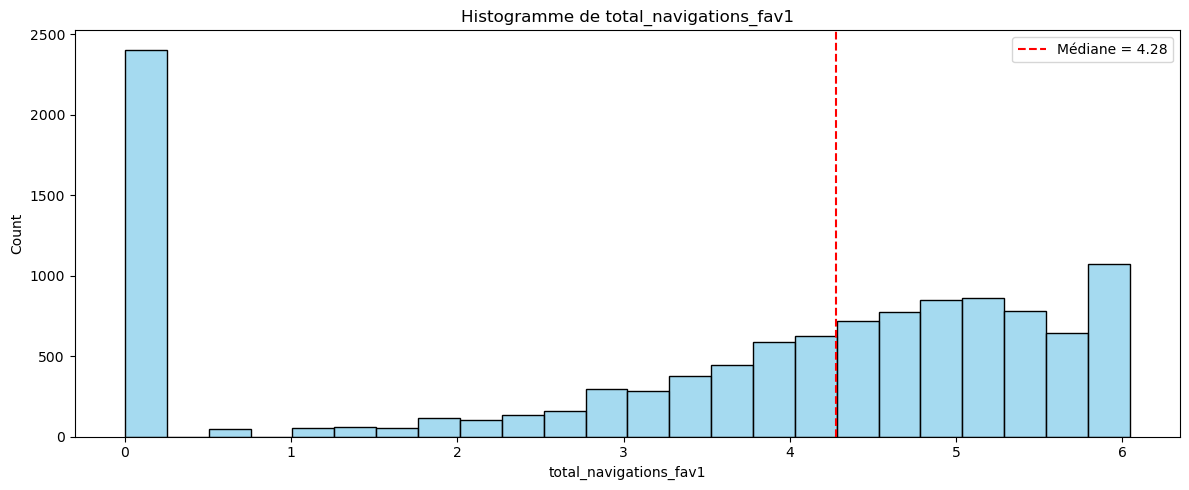


Analyse de la variable : total_navigations_fav2
------------------------------------------------------------
Médiane de total_navigations_fav2 : 2.30


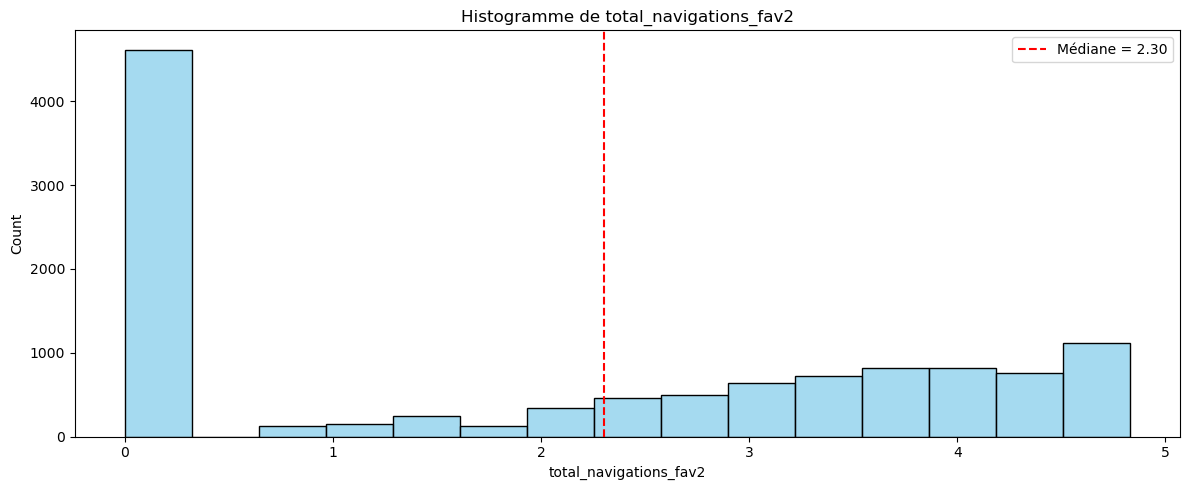


Analyse de la variable : driven_km_drives
------------------------------------------------------------
Médiane de driven_km_drives : 0.00


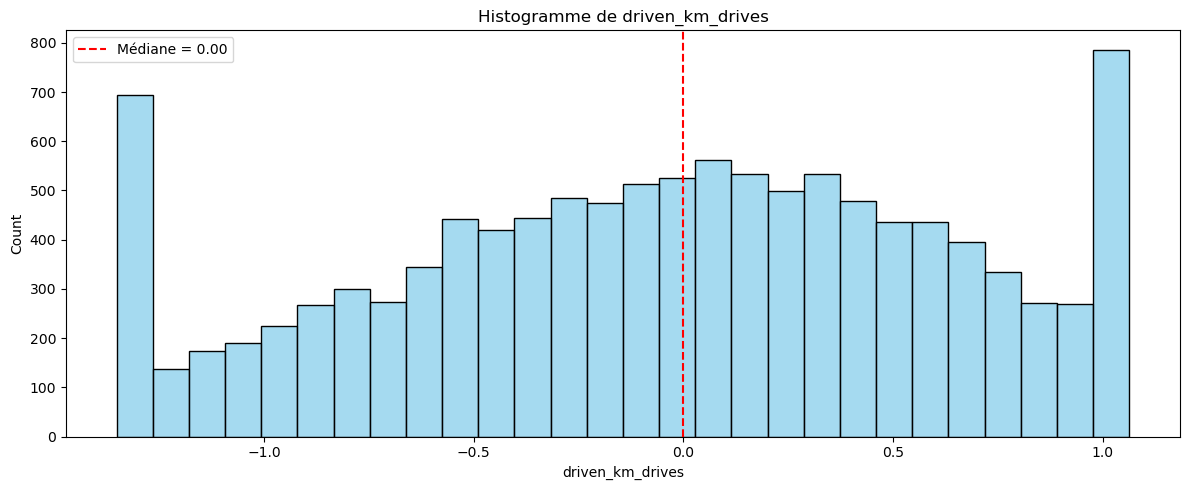


Analyse de la variable : duration_minutes_drives
------------------------------------------------------------
Médiane de duration_minutes_drives : 0.00


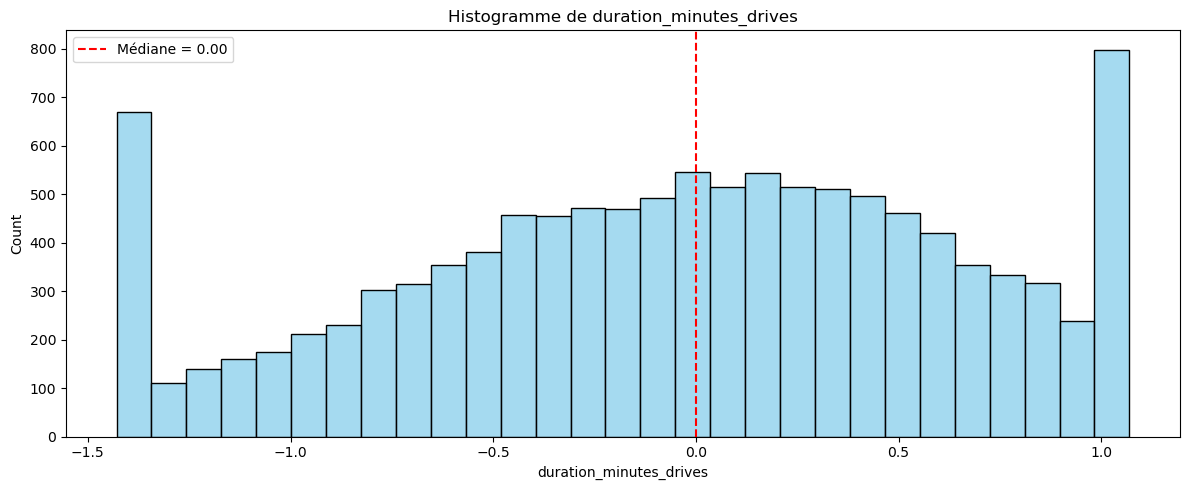

In [571]:
analyse_distribution(data, colonnes)

# 3. Encodage des Variables Catégorielles

In [109]:
# 2. Encodage de la cible
label_mapping = {'retained': 0, 'churned': 1}
data['label'] = data['label'].map(label_mapping)
test_waze['label'] = test_waze['label'].map(label_mapping)
df_unlabeled['label'] = df_unlabeled['label'].map(label_mapping)

# 3. Encodage OneHot des colonnes catégorielles
cols_to_encode = ['device']  # ajoute d'autres colonnes si besoin

encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
encoded_data = encoder.fit_transform(data[cols_to_encode])
encoded_test = encoder.transform(test_waze[cols_to_encode])
encoded_df_unlabeled = encoder.transform(df_unlabeled[cols_to_encode])

encoded_data_df = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(cols_to_encode), index=data.index)
encoded_test_df = pd.DataFrame(encoded_test, columns=encoder.get_feature_names_out(cols_to_encode), index=test_waze.index)
encoded_df_unlabeled = pd.DataFrame(encoded_df_unlabeled, columns=encoder.get_feature_names_out(cols_to_encode), index=df_unlabeled.index)

data = pd.concat([data.drop(cols_to_encode, axis=1), encoded_data_df], axis=1)
test_waze = pd.concat([test_waze.drop(cols_to_encode, axis=1), encoded_test_df], axis=1)
df_unlabeled = pd.concat([df_unlabeled.drop(cols_to_encode, axis=1), encoded_df_unlabeled], axis=1)



In [111]:
print(len(test_waze))

2860


In [113]:
for k, v in label_mapping.items():
    print(f"{k}-->{v}")

retained-->0
churned-->1


In [115]:
print(encoder.categories_)
print(encoded_data)
print("---")
print(encoded_test)

[array(['Android', 'iPhone'], dtype=object)]
[[1.]
 [1.]
 [1.]
 ...
 [1.]
 [0.]
 [1.]]
---
[[0.]
 [0.]
 [0.]
 ...
 [1.]
 [1.]
 [1.]]


In [117]:
encoder.get_feature_names_out(['device'])

array(['device_iPhone'], dtype=object)

In [119]:
print(data.dtypes)

sessions                     int64
drives                     float64
total_sessions             float64
n_days_after_onboarding      int64
total_navigations_fav1     float64
total_navigations_fav2     float64
driven_km_drives           float64
duration_minutes_drives    float64
activity_days                int64
driving_days                 int64
label                        int64
device_iPhone              float64
dtype: object


In [121]:
data.head()

,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,label,device_iPhone
2130,109,0.398203,0.185470,1164,5.398163,0.000000,1.059318,1.069555,21,17,1,1.0
3660,120,0.603140,0.057618,2094,4.248495,4.663439,-0.673386,-0.925670,17,13,0,1.0
1625,107,0.383039,-0.189934,977,0.000000,4.828314,0.803790,1.069555,2,2,0,1.0
6987,79,0.178188,-0.353389,1166,4.219508,2.484907,-0.289164,-0.392950,15,10,0,1.0
12113,59,0.026692,0.730730,10,3.970292,0.000000,-0.224190,-0.192053,10,6,1,1.0


In [123]:
print(len(test_waze))

2860


# 4. Feature Engineering

In [127]:
data['total_navigations'] = data['total_navigations_fav1'] + data['total_navigations_fav2']

data['activity_ratio'] = data['activity_days'] / data['n_days_after_onboarding']

data['session_efficiency'] = data['drives'] / (data['sessions'] + 1e-6)  

data['km_per_session'] = data['driven_km_drives'] / data['sessions']

In [129]:
X_train = data.drop(columns='label')
y_train = data['label']

# **SelectKBest**

In [132]:
#  On retire la colonne 'device' de X_train_resampled
X_features_only = X_train

# Sélection de k meilleures variables avec 
k = 11 # Choisis le nombre de features que tu veux conserver
selector = SelectKBest(score_func=f_classif, k=k)

# Application du sélecteur
X_selected = selector.fit_transform(X_features_only, y_train)

# Obtenir les noms des colonnes sélectionnées
mask = selector.get_support()
selected_features = X_features_only.columns[mask]

# Affichage
print(" Variables sélectionnées :")
print(selected_features)


 Variables sélectionnées :
Index(['sessions', 'drives', 'total_sessions', 'n_days_after_onboarding',
       'total_navigations_fav1', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'total_navigations', 'km_per_session'],
      dtype='object')


In [134]:
# X : DataFrame avec les variables explicatives
# y : série ou colonne cible (encodée si elle est catégorique)

# Étape 1 : Calculer les scores F et p-values
F_values, p_values = f_classif(X_train, y_train)

# Étape 2 : Créer un DataFrame pour visualiser
feature_scores = pd.DataFrame({
    'Feature': X_train.columns,
    'F_value': F_values,
    'p_value': p_values
})

# Étape 3 : Filtrer les variables dont la p-value est < 0.05
selected_features = feature_scores[feature_scores['p_value'] < 0.05]['Feature'].values

# Étape 4 : Garder seulement les colonnes pertinentes
X_selected = X_train[selected_features]

# Afficher les variables sélectionnées
print("Variables sélectionnées :", selected_features)

Variables sélectionnées : ['sessions' 'drives' 'total_sessions' 'n_days_after_onboarding'
 'total_navigations_fav1' 'driven_km_drives' 'duration_minutes_drives'
 'activity_days' 'driving_days' 'total_navigations' 'km_per_session']


In [136]:
print(data.dtypes)

sessions                     int64
drives                     float64
total_sessions             float64
n_days_after_onboarding      int64
total_navigations_fav1     float64
total_navigations_fav2     float64
driven_km_drives           float64
duration_minutes_drives    float64
activity_days                int64
driving_days                 int64
label                        int64
device_iPhone              float64
total_navigations          float64
activity_ratio             float64
session_efficiency         float64
km_per_session             float64
dtype: object


In [138]:
#data = data.drop('total_navigations_fav1', axis=1)
#data = data.drop('total_navigations_fav2', axis=1)
#data = data.drop('sessions', axis=1)
#data = data.drop('activity_days', axis=1)
#data = data.drop('n_days_after_onboarding', axis=1)
#data = data.drop('drives', axis=1)
#data = data.drop('driven_km_drives', axis=1)
#data = data.drop('total_sessions', axis=1)
data = data.drop('device_iPhone', axis=1)
data = data.drop('total_navigations_fav2', axis=1)
data = data.drop('activity_ratio', axis=1)
data = data.drop('session_efficiency', axis=1)

In [140]:
test_waze['total_navigations'] = test_waze['total_navigations_fav1'] + test_waze['total_navigations_fav2']

test_waze['activity_ratio'] = test_waze['activity_days'] / test_waze['n_days_after_onboarding']

test_waze['session_efficiency'] = test_waze['drives'] / (test_waze['sessions'] + 1e-6)  # Évite la division par zéro

test_waze['km_per_session'] = test_waze['driven_km_drives'] / test_waze['sessions']



In [142]:
df_unlabeled['total_navigations'] = df_unlabeled['total_navigations_fav1'] + df_unlabeled['total_navigations_fav2']

df_unlabeled['activity_ratio'] = df_unlabeled['activity_days'] / df_unlabeled['n_days_after_onboarding']

df_unlabeled['session_efficiency'] = df_unlabeled['drives'] / (df_unlabeled['sessions'] + 1e-6)  # Évite la division par zéro

df_unlabeled['km_per_session'] = df_unlabeled['driven_km_drives'] / df_unlabeled['sessions']

In [144]:
#test_waze = test_waze.drop('total_navigations_fav1', axis=1)
#test_waze = test_waze.drop('total_navigations_fav2', axis=1)
#test_waze = test_waze.drop('sessions', axis=1)
#test_waze = test_waze.drop('activity_days', axis=1)
#test_waze = test_waze.drop('n_days_after_onboarding', axis=1)
#test_waze = test_waze.drop('drives', axis=1)
#test_waze = test_waze.drop('driven_km_drives', axis=1)
#test_waze = test_waze.drop('total_sessions', axis=1)
test_waze = test_waze.drop('device_iPhone', axis=1)
test_waze = test_waze.drop('total_navigations_fav2', axis=1)
test_waze = test_waze.drop('activity_ratio', axis=1)
test_waze = test_waze.drop('session_efficiency', axis=1)

df_unlabeled = df_unlabeled.drop('device_iPhone', axis=1)
df_unlabeled = df_unlabeled.drop('total_navigations_fav2', axis=1)
df_unlabeled = df_unlabeled.drop('activity_ratio', axis=1)
df_unlabeled = df_unlabeled.drop('session_efficiency', axis=1)

In [146]:
print(len(test_waze))

2860



# 5. Normalisation

In [148]:
numerical_cols = data.select_dtypes(include=['float64', 'int64']).columns.tolist()
if 'label' in numerical_cols:
    numerical_cols.remove('label')
if 'device_iPhone' in numerical_cols:
    numerical_cols.remove('device_iPhone')  # ne pas scaler 'device' car catégorielle

# Normalisation des colonnes numériques
scaler = MinMaxScaler()
data[numerical_cols] = scaler.fit_transform(data[numerical_cols])
test_waze[numerical_cols] = scaler.transform(test_waze[numerical_cols])
df_unlabeled[numerical_cols] = scaler.transform(df_unlabeled[numerical_cols])

In [150]:
print(len(test_waze))

2860



=== VÉRIFICATION FINALE ===
Dimensions finales : (11439, 12)

Aperçu des données transformées :


,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,driven_km_drives,duration_minutes_drives,activity_days,driving_days,label,total_navigations,km_per_session
2130,0.439331,0.778408,0.663430,0.331808,0.892996,0.998102,1.000000,0.677419,0.566667,1,0.496460,0.575646
3660,0.485356,0.861449,0.613440,0.597826,0.702811,0.280776,0.201509,0.548387,0.433333,0,0.819615,0.550260
1625,0.430962,0.772263,0.516648,0.278318,0.000000,0.892315,1.000000,0.064516,0.066667,0,0.444052,0.571992
6987,0.313808,0.689257,0.452738,0.332380,0.698016,0.439841,0.414704,0.483871,0.333333,0,0.616593,0.553491
12113,0.230126,0.627871,0.876625,0.001716,0.656789,0.466740,0.495103,0.322581,0.200000,1,0.365141,0.553260



Statistiques descriptives :


,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,driven_km_drives,duration_minutes_drives,activity_days,driving_days,label,total_navigations,km_per_session
count,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000,11439.000000
mean,0.304403,0.577435,0.562060,0.501206,0.588027,0.540727,0.552365,0.502173,0.406332,0.177376,0.514864,0.556240
std,0.280630,0.277774,0.274669,0.288529,0.346364,0.278691,0.275352,0.290733,0.260952,0.382003,0.257784,0.082619
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.079498,0.387983,0.379040,0.253003,0.380907,0.342195,0.362372,0.258065,0.166667,0.000000,0.356028,0.544764
50%,0.221757,0.617055,0.590912,0.502002,0.707471,0.559553,0.571963,0.516129,0.400000,0.000000,0.504427,0.559553
75%,0.447699,0.793185,0.770037,0.751144,0.857201,0.756186,0.762573,0.741935,0.633333,0.000000,0.732721,0.572052
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


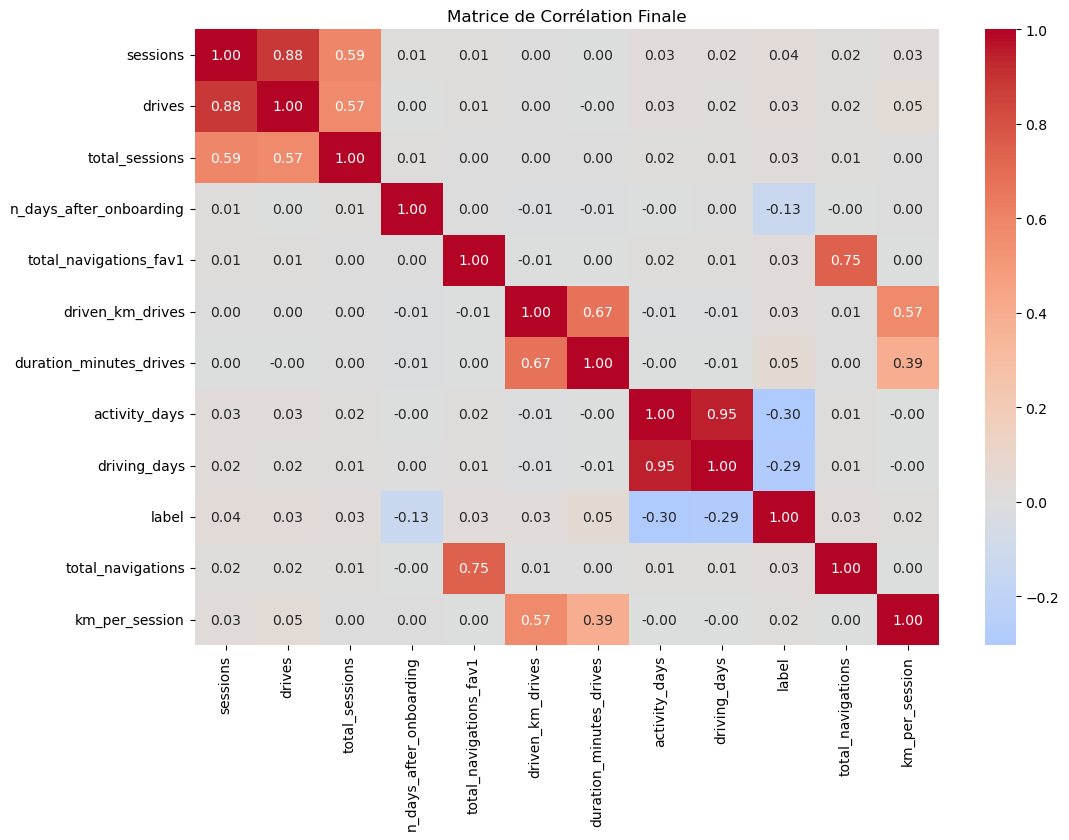

In [152]:
print("\n=== VÉRIFICATION FINALE ===")
print(f"Dimensions finales : {data.shape}")
print("\nAperçu des données transformées :")
display(data.head())

print("\nStatistiques descriptives :")
display(data.describe())

# Visualisation
plt.figure(figsize=(12,8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap='coolwarm', center=0)
plt.title("Matrice de Corrélation Finale")
plt.show()

# **SMOTENC**

In [155]:
# --- 1. Séparer les features et la cible
X_train = data.drop(columns='label')
y_train = data['label']

# --- 2. Comme il n'y a pas de variables catégorielles, on utilise SMOTE simple
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# --- 3. Vérification de l'équilibrage
print("Avant SMOTE :", y_train.value_counts().to_dict())
print("Après SMOTE :", y_train_resampled.value_counts().to_dict())

Avant SMOTE : {0: 9410, 1: 2029}
Après SMOTE : {1: 9410, 0: 9410}


Le déséquilibre a été corrigé efficacement.
 train_data est maintenant équilibré et prêt pour l'entraînement de modèles fiables.

In [158]:
print(len(test_waze))

2860


In [160]:
data.head(100)

,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,driven_km_drives,duration_minutes_drives,activity_days,driving_days,label,total_navigations,km_per_session
2130,0.439331,0.778408,0.663430,0.331808,0.892996,0.998102,1.000000,0.677419,0.566667,1,0.496460,0.575646
3660,0.485356,0.861449,0.613440,0.597826,0.702811,0.280776,0.201509,0.548387,0.433333,0,0.819615,0.550260
1625,0.430962,0.772263,0.516648,0.278318,0.000000,0.892315,1.000000,0.064516,0.066667,0,0.444052,0.571992
6987,0.313808,0.689257,0.452738,0.332380,0.698016,0.439841,0.414704,0.483871,0.333333,0,0.616593,0.553491
12113,0.230126,0.627871,0.876625,0.001716,0.656789,0.466740,0.495103,0.322581,0.200000,1,0.365141,0.553260
...,...,...,...,...,...,...,...,...,...,...,...,...
14185,0.456067,0.787371,0.643222,0.808066,1.000000,0.911086,0.885954,0.612903,0.333333,0,0.919337,0.571996
4803,0.343096,0.732137,0.526657,0.754577,0.874816,0.731580,0.443129,0.709677,0.733333,0,0.813332,0.567554
10633,0.117155,0.455928,0.513493,0.603833,0.875649,0.806372,0.970664,0.000000,0.000000,0,0.486816,0.590405
13999,0.196653,0.575380,0.356643,0.782323,0.000000,0.470515,0.479496,0.032258,0.033333,0,0.000000,0.552569


In [162]:
print(data.dtypes)


sessions                   float64
drives                     float64
total_sessions             float64
n_days_after_onboarding    float64
total_navigations_fav1     float64
driven_km_drives           float64
duration_minutes_drives    float64
activity_days              float64
driving_days               float64
label                        int64
total_navigations          float64
km_per_session             float64
dtype: object


In [164]:
print(X_train_resampled.columns)


Index(['sessions', 'drives', 'total_sessions', 'n_days_after_onboarding',
       'total_navigations_fav1', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'total_navigations', 'km_per_session'],
      dtype='object')


In [166]:
print(len(test_waze))

2860


In [168]:
# Fusionner X et y en un seul DataFrame pour plus de simplicité
train_resampled = X_train_resampled.copy()
train_resampled['label'] = y_train_resampled

# Enregistrer dans un fichier CSV
train_resampled.to_csv("train_resampled.csv", index=False)
# Enregistrer dans un fichier CSV
test_waze.to_csv("test.csv", index=False)
df_unlabeled.to_csv("df_unlabeled.csv", index=False)



In [638]:
test = pd.read_csv("test.csv")
print(len(test))

2860


In [640]:
print(len(test_waze))

2860
